## 1. Parámetros del experimento y generación de los niveles de temperatura

In [ ]:
import math
import random
import statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

MATRICULA = 2143252
TAMANOS = [5, 10, 15]
REPLICAS = 10
N_ITER = 300
T_FINAL = 0.01

random.seed(MATRICULA)
r = random.random()
print(f"r = {r:.6f}  (se genera una sola vez y se usa en todo el experimento)")

T_MIN, T_MAX = 0.5, 9.0
FRACCIONES = {"bajo": 0.3 * r, "medio": 0.3 * r + 0.3, "alto": 0.3 * r + 0.6}
NIVELES = {k: T_MIN + f * (T_MAX - T_MIN) for k, f in FRACCIONES.items()}

print(f"Rango de temperatura: [{T_MIN}, {T_MAX}]")
for k in NIVELES:
    print(f"  {k:<6} fraccion = {FRACCIONES[k]:.4f}  ->  T0 = {NIVELES[k]:.4f}")

r = 0.343784  (se genera una sola vez y se usa en todo el experimento)
Rango de temperatura: [0.5, 9.0]
  bajo   fraccion = 0.1031  ->  T0 = 1.3766
  medio  fraccion = 0.4031  ->  T0 = 3.9266
  alto   fraccion = 0.7031  ->  T0 = 6.4766


## 2. Código del Recocido Simulado con 2-opt



In [ ]:
def make_instance(n, seed):
    rng = random.Random(seed)
    return [(rng.uniform(0, 10), rng.uniform(0, 10)) for _ in range(n)]


def tour_length(points, route):
    return sum(math.dist(points[route[i]], points[route[(i + 1) % len(route)]])
               for i in range(len(route)))


def simulated_annealing(points, T0, Tf, n_iter, seed):
    rng = random.Random(seed)
    n = len(points)
    current = list(range(n))
    rng.shuffle(current)
    L = tour_length(points, current)
    best = L
    factor = (Tf / T0) ** (1.0 / n_iter)
    T = T0
    for _ in range(n_iter):
        i, k = sorted(rng.sample(range(1, n), 2))
        while i == 1 and k == n - 1:
            i, k = sorted(rng.sample(range(1, n), 2))
        a, b = points[current[i - 1]], points[current[i]]
        c, d = points[current[k]], points[current[(k + 1) % n]]
        dL = (math.dist(a, c) + math.dist(b, d)) - (math.dist(a, b) + math.dist(c, d))
        if dL < 0 or rng.random() < math.exp(-dL / T):
            current[i:k + 1] = current[i:k + 1][::-1]
            L += dL
            if L < best:
                best = L
        T *= factor
    return best


def optimal_length(points):
    n = len(points)
    D = [[math.dist(points[i], points[j]) for j in range(n)] for i in range(n)]
    INF = float("inf")
    size = 1 << (n - 1)
    dp = [[INF] * (n - 1) for _ in range(size)]
    for j in range(n - 1):
        dp[1 << j][j] = D[0][j + 1]
    for mask in range(1, size):
        for j in range(n - 1):
            cur = dp[mask][j]
            if cur == INF or not (mask >> j) & 1:
                continue
            for k in range(n - 1):
                if (mask >> k) & 1:
                    continue
                nm = mask | (1 << k)
                val = cur + D[j + 1][k + 1]
                if val < dp[nm][k]:
                    dp[nm][k] = val
    full = size - 1
    return min(dp[full][j] + D[j + 1][0] for j in range(n - 1))


INST = {n: make_instance(n, MATRICULA + n) for n in TAMANOS}
OPT = {n: optimal_length(INST[n]) for n in TAMANOS}
for n in TAMANOS:
    print(f"n = {n:>2}: optimo exacto (programacion dinamica) = {OPT[n]:.3f}")

n =  5: optimo exacto (programacion dinamica) = 28.972
n = 10: optimo exacto (programacion dinamica) = 30.974
n = 15: optimo exacto (programacion dinamica) = 34.871


## 3. Calibración piloto


In [ ]:
ups = []
for n in TAMANOS:
    rng = random.Random(99 + n)
    pts = INST[n]
    for _ in range(4000):
        cur = list(range(n))
        rng.shuffle(cur)
        i, k = sorted(rng.sample(range(1, n), 2))
        if i == 1 and k == n - 1:
            continue
        a, b = pts[cur[i - 1]], pts[cur[i]]
        c, d = pts[cur[k]], pts[cur[(k + 1) % n]]
        dL = (math.dist(a, c) + math.dist(b, d)) - (math.dist(a, b) + math.dist(c, d))
        if dL > 0:
            ups.append(dL)
delta_medio = statistics.mean(ups)
print(f"Alargamiento promedio de un movimiento que empeora: {delta_medio:.2f}")
for T in (T_MIN, T_MAX):
    print(f"  T = {T:<4} -> probabilidad de aceptar un empeoramiento promedio: {math.exp(-delta_medio / T):.2%}")

Alargamiento promedio de un movimiento que empeora: 3.24
  T = 0.5  -> probabilidad de aceptar un empeoramiento promedio: 0.15%
  T = 9.0  -> probabilidad de aceptar un empeoramiento promedio: 69.79%


--- 100 iteraciones: brecha media (%) sobre el optimo ---
n       5    10    15
T0                   
0.05   0.0  3.3  25.7
0.10   0.0  3.7  24.1
0.25   0.0  3.3  26.2
0.50   0.0  3.1  26.2
1.00   0.0  3.5  23.6
2.00  -0.0  2.8  27.6
4.00  -0.0  3.4  28.7
8.00  -0.0  4.3  29.2
16.00 -0.0  4.7  29.8
32.00 -0.0  4.5  27.6

--- 300 iteraciones: brecha media (%) sobre el optimo ---
n       5    10    15
T0                   
0.05   0.0  1.3   5.3
0.10   0.0  1.3   4.9
0.25   0.0  1.3   5.2
0.50   0.0  1.2   5.1
1.00   0.0  1.3   5.5
2.00  -0.0  1.2   6.9
4.00  -0.0  0.9   6.8
8.00  -0.0  0.9   9.1
16.00 -0.0  1.1   9.5
32.00 -0.0  1.0  10.1

--- 1000 iteraciones: brecha media (%) sobre el optimo ---
n       5    10   15
T0                  
0.05   0.0  1.3  1.4
0.10   0.0  1.3  1.4
0.25   0.0  1.2  1.4
0.50   0.0  1.2  0.6
1.00  -0.0  0.9  1.2
2.00  -0.0  0.6  1.1
4.00  -0.0  0.4  0.9
8.00  -0.0  0.6  1.4
16.00 -0.0  0.4  1.1
32.00 -0.0  0.7  2.7



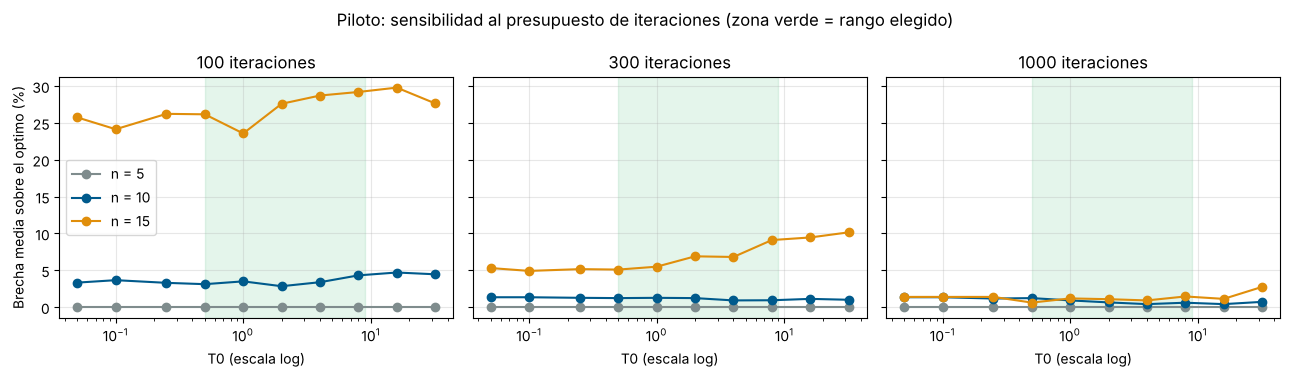

In [ ]:
GRILLA = [0.05, 0.1, 0.25, 0.5, 1, 2, 4, 8, 16, 32]
piloto = []
for N in (100, 300, 1000):
    for n in TAMANOS:
        for T0 in GRILLA:
            costos = [simulated_annealing(INST[n], T0, T_FINAL, N, 10**7 + 1000 * n + s) for s in range(30)]
            piloto.append({"N": N, "n": n, "T0": T0,
                           "brecha": (statistics.mean(costos) - OPT[n]) / OPT[n] * 100,
                           "desv": statistics.stdev(costos)})
piloto = pd.DataFrame(piloto)
for N in (100, 300, 1000):
    tabla = piloto[piloto.N == N].pivot(index="T0", columns="n", values="brecha").round(1)
    print(f"--- {N} iteraciones: brecha media (%) sobre el optimo ---")
    print(tabla.to_string())
    print()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, N in zip(axes, (100, 300, 1000)):
    for n, col in zip(TAMANOS, ["#7F8C8D", "#005A8C", "#E08E0B"]):
        sub = piloto[(piloto.N == N) & (piloto.n == n)]
        ax.plot(sub["T0"], sub["brecha"], "o-", color=col, label=f"n = {n}")
    ax.axvspan(T_MIN, T_MAX, color="#27AE60", alpha=0.12)
    ax.set_xscale("log")
    ax.set_title(f"{N} iteraciones")
    ax.set_xlabel("T0 (escala log)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Brecha media sobre el optimo (%)")
axes[0].legend()
fig.suptitle("Piloto: sensibilidad al presupuesto de iteraciones (zona verde = rango elegido)")
fig.tight_layout()
fig.savefig("fig_piloto.png", dpi=150)
plt.show()

## 4. Experimento factorial completo 3 × 3

In [ ]:
filas = []
corrida = 0
for n in TAMANOS:
    for nivel, T0 in NIVELES.items():
        for rep in range(1, REPLICAS + 1):
            semilla = MATRICULA * 1000 + corrida
            costo = simulated_annealing(INST[n], T0, T_FINAL, N_ITER, semilla)
            filas.append({"corrida": corrida + 1, "tamano": n, "temperatura": nivel, "T0": round(T0, 4),
                          "replica": rep, "semilla": semilla, "costo": costo,
                          "brecha": (costo - OPT[n]) / OPT[n] * 100})
            corrida += 1

df = pd.DataFrame(filas)
df["temperatura"] = pd.Categorical(df["temperatura"], ["bajo", "medio", "alto"], ordered=True)
df.to_csv("resultados_90_corridas.csv", index=False)
print(f"Corridas totales: {len(df)}")
resumen = df.groupby(["tamano", "temperatura"], observed=True)["costo"].agg(["mean", "median", "std", "min", "max"]).round(3)
print(resumen.to_string())

Corridas totales: 90
                      mean  median    std     min     max
tamano temperatura                                       
5      bajo         28.972  28.972  0.000  28.972  28.972
       medio        28.972  28.972  0.000  28.972  28.972
       alto         28.972  28.972  0.000  28.972  28.972
10     bajo         31.191  30.974  0.280  30.974  31.517
       medio        31.410  31.517  0.433  30.974  32.136
       alto         31.246  31.246  0.286  30.974  31.517
15     bajo         35.809  35.482  0.970  34.871  37.103
       medio        36.425  36.017  1.620  34.871  39.636
       alto         37.509  36.571  3.111  34.871  43.570


## 5. ANOVA de dos factores, α = 0.05


In [ ]:
modelo = ols("costo ~ C(temperatura) * C(tamano)", data=df).fit()
tabla_anova = sm.stats.anova_lm(modelo, typ=2)
tabla_anova["% variacion"] = tabla_anova["sum_sq"] / tabla_anova["sum_sq"].sum() * 100
print(tabla_anova.round(4).to_string())

p_temp = tabla_anova.loc["C(temperatura)", "PR(>F)"]
p_tam = tabla_anova.loc["C(tamano)", "PR(>F)"]
p_int = tabla_anova.loc["C(temperatura):C(tamano)", "PR(>F)"]
print()
for nombre, p in [("temperatura", p_temp), ("tamano", p_tam), ("interaccion", p_int)]:
    print(f"{nombre:<12} p = {p:.4g} -> {'SIGNIFICATIVO' if p < 0.05 else 'no significativo'} (alfa = 0.05)")

                            sum_sq    df         F  PR(>F)  % variacion
C(temperatura)              5.1302   2.0    1.6982  0.1895       0.4883
C(tamano)                 913.2466   2.0  302.3009  0.0000      86.9209
C(temperatura):C(tamano)    9.9376   4.0    1.6448  0.1710       0.9458
Residual                  122.3499  81.0       NaN     NaN      11.6450

temperatura  p = 0.1895 -> no significativo (alfa = 0.05)
tamano       p = 2.709e-38 -> SIGNIFICATIVO (alfa = 0.05)
interaccion  p = 0.171 -> no significativo (alfa = 0.05)


In [ ]:
w, p_sh = stats.shapiro(modelo.resid)
grupos = [g["costo"].values for _, g in df.groupby(["tamano", "temperatura"], observed=True)]
lev_stat, p_lev = stats.levene(*grupos)
print(f"Shapiro-Wilk (normalidad de residuos): W = {w:.3f}, p = {p_sh:.4g}")
print(f"Levene (homogeneidad de varianzas entre las 9 celdas): p = {p_lev:.4g}")
print()

modelo_brecha = ols("brecha ~ C(temperatura) * C(tamano)", data=df).fit()
anova_brecha = sm.stats.anova_lm(modelo_brecha, typ=2)
print("ANOVA de robustez con la brecha porcentual (%) como respuesta:")
print(anova_brecha.round(4).to_string())

Shapiro-Wilk (normalidad de residuos): W = 0.724, p = 1.011e-11
Levene (homogeneidad de varianzas entre las 9 celdas): p = 6.625e-06

ANOVA de robustez con la brecha porcentual (%) como respuesta:
                             sum_sq    df        F  PR(>F)
C(temperatura)              42.4917   2.0   1.6987  0.1894
C(tamano)                  403.3496   2.0  16.1252  0.0000
C(temperatura):C(tamano)    81.9957   4.0   1.6390  0.1724
Residual                  1013.0529  81.0      NaN     NaN


## 6. Efecto de la temperatura dentro de cada tamaño y bootstrap de la mediana

In [ ]:
def bootstrap_mediana(x, B=10000, seed=0):
    rng = random.Random(seed)
    x = list(x)
    meds = sorted(statistics.median(rng.choices(x, k=len(x))) for _ in range(B))
    return statistics.median(x), meds[int(0.025 * B)], meds[int(0.975 * B) - 1]


efectos = []
for n in TAMANOS:
    sub = df[df.tamano == n]
    g = [sub[sub.temperatura == t]["costo"].values for t in ["bajo", "medio", "alto"]]
    if len(set(sub["costo"].round(9))) == 1:
        F, p = float("nan"), 1.0
    else:
        F, p = stats.f_oneway(*g)
    efectos.append({"tamano": n, "F": F, "p_valor": p, "significativo_bonferroni": p < 0.05 / 3})
efectos = pd.DataFrame(efectos)
print("Efecto de la temperatura dentro de cada tamano (ANOVA de una via):")
print(efectos.round(4).to_string(index=False))

print()
for n in TAMANOS:
    sub = df[df.tamano == n]
    if len(set(sub["costo"].round(9))) > 1 and efectos.loc[efectos.tamano == n, "p_valor"].iloc[0] < 0.05:
        print(f"Tukey HSD, n = {n}:")
        print(pairwise_tukeyhsd(sub["costo"], sub["temperatura"].astype(str)).summary())
        print()

hay_interaccion = p_int < 0.05
hay_temp = p_temp < 0.05
boot = []
for n in TAMANOS:
    for t in ["bajo", "medio", "alto"]:
        x = df[(df.tamano == n) & (df.temperatura == t)]["costo"].values
        med, lo, hi = bootstrap_mediana(x, seed=MATRICULA + 10 * n + len(t))
        sig_n = bool(efectos.loc[efectos.tamano == n, "significativo_bonferroni"].iloc[0])
        justificado = hay_interaccion and sig_n or (not hay_interaccion and hay_temp)
        boot.append({"tamano": n, "temperatura": t, "T0": round(NIVELES[t], 3), "mediana": med,
                     "IC95_inf": lo, "IC95_sup": hi, "media": x.mean(), "desv": x.std(ddof=1),
                     "justificado_por_ANOVA": justificado})
boot = pd.DataFrame(boot)
boot.to_csv("resultados_bootstrap.csv", index=False)
print("Bootstrap (10,000 remuestreos) de la mediana del costo por punto de diseno:")
print(boot.round(3).to_string(index=False))

Efecto de la temperatura dentro de cada tamano (ANOVA de una via):
 tamano      F  p_valor  significativo_bonferroni
      5    NaN   1.0000                     False
     10 1.1257   0.3392                     False
     15 1.6766   0.2059                     False

Bootstrap (10,000 remuestreos) de la mediana del costo por punto de diseno:
 tamano temperatura    T0  mediana  IC95_inf  IC95_sup  media  desv  justificado_por_ANOVA
      5        bajo 1.377   28.972    28.972    28.972 28.972 0.000                  False
      5       medio 3.927   28.972    28.972    28.972 28.972 0.000                  False
      5        alto 6.477   28.972    28.972    28.972 28.972 0.000                  False
     10        bajo 1.377   30.974    30.974    31.517 31.191 0.280                  False
     10       medio 3.927   31.517    30.974    31.761 31.410 0.433                  False
     10        alto 6.477   31.246    30.974    31.517 31.246 0.286                  False
     15        bajo

In [ ]:
for n in (10, 15):
    sub = df[df.tamano == n]
    g = [sub[sub.temperatura == t]["costo"].values for t in ["bajo", "medio", "alto"]]
    kw = stats.kruskal(*g)
    rho, p_rho = stats.spearmanr(sub["T0"], sub["costo"])
    print(f"n = {n}: Kruskal-Wallis H = {kw.statistic:.3f}, p = {kw.pvalue:.4f}  |  Spearman (T0 vs costo) rho = {rho:.3f}, p = {p_rho:.4f}")
print("n = 5: sin variacion (todas las corridas dan el optimo exacto), no aplica.")

n = 10: Kruskal-Wallis H = 0.648, p = 0.7233  |  Spearman (T0 vs costo) rho = 0.116, p = 0.5417
n = 15: Kruskal-Wallis H = 1.149, p = 0.5631  |  Spearman (T0 vs costo) rho = 0.198, p = 0.2934
n = 5: sin variacion (todas las corridas dan el optimo exacto), no aplica.


## 7. Gráficas

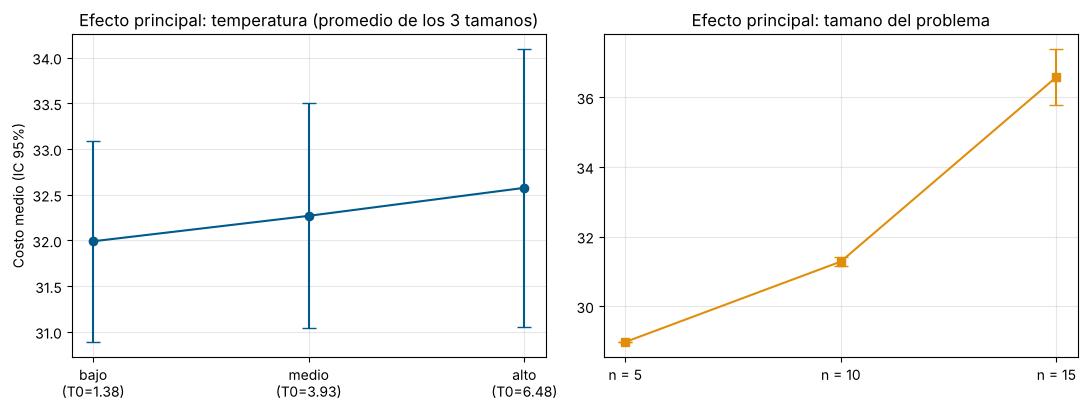

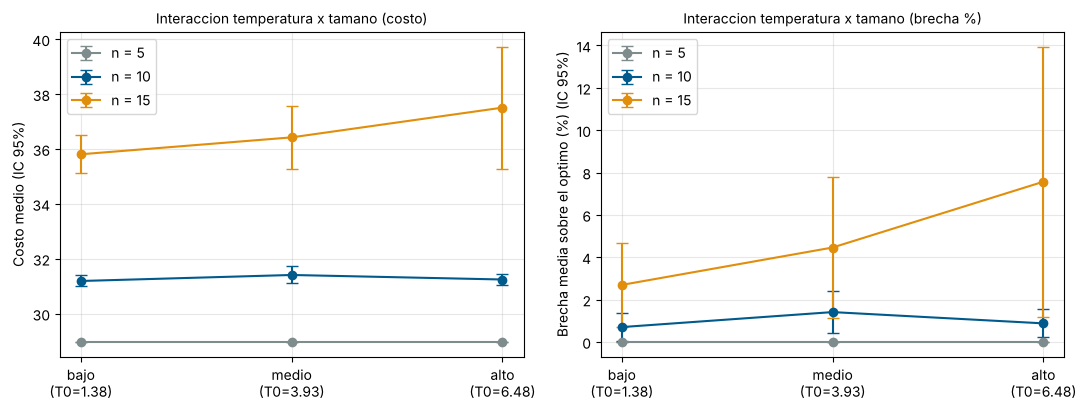

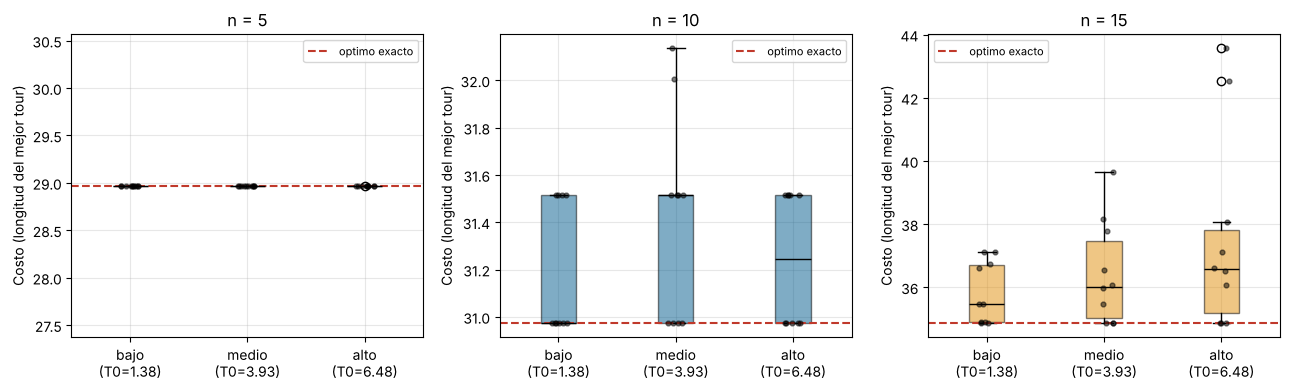

In [ ]:
COLORES = {5: "#7F8C8D", 10: "#005A8C", 15: "#E08E0B"}
ETIQ = [f"{t}\n(T0={NIVELES[t]:.2f})" for t in ["bajo", "medio", "alto"]]


def media_ic(x):
    x = np.asarray(x, dtype=float)
    if len(x) < 2 or x.std(ddof=1) == 0:
        return x.mean(), 0.0
    return x.mean(), stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / math.sqrt(len(x))


fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
m = [media_ic(df[df.temperatura == t]["costo"]) for t in ["bajo", "medio", "alto"]]
axes[0].errorbar(range(3), [a for a, _ in m], yerr=[b for _, b in m], fmt="o-", color="#005A8C", capsize=5)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(ETIQ)
axes[0].set_title("Efecto principal: temperatura (promedio de los 3 tamanos)")
axes[0].set_ylabel("Costo medio (IC 95%)")
m = [media_ic(df[df.tamano == n]["costo"]) for n in TAMANOS]
axes[1].errorbar(range(3), [a for a, _ in m], yerr=[b for _, b in m], fmt="s-", color="#E08E0B", capsize=5)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels([f"n = {n}" for n in TAMANOS])
axes[1].set_title("Efecto principal: tamano del problema")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig_efectos_principales.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for col, ax, titulo, yl in [("costo", axes[0], "Interaccion temperatura x tamano (costo)", "Costo medio (IC 95%)"),
                            ("brecha", axes[1], "Interaccion temperatura x tamano (brecha %)", "Brecha media sobre el optimo (%) (IC 95%)")]:
    for n in TAMANOS:
        mm = [media_ic(df[(df.tamano == n) & (df.temperatura == t)][col]) for t in ["bajo", "medio", "alto"]]
        ax.errorbar(range(3), [a for a, _ in mm], yerr=[b for _, b in mm], fmt="o-", color=COLORES[n],
                    capsize=4, label=f"n = {n}")
    ax.set_xticks(range(3))
    ax.set_xticklabels(ETIQ)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylabel(yl)
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig("fig_interaccion.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
rng_j = np.random.default_rng(0)
for ax, n in zip(axes, TAMANOS):
    datos = [df[(df.tamano == n) & (df.temperatura == t)]["costo"].values for t in ["bajo", "medio", "alto"]]
    ax.boxplot(datos, tick_labels=ETIQ, patch_artist=True,
               boxprops=dict(facecolor=COLORES[n], alpha=0.5), medianprops=dict(color="black"))
    for i, d in enumerate(datos, start=1):
        ax.scatter(i + rng_j.uniform(-0.08, 0.08, len(d)), d, s=12, color="black", alpha=0.5, zorder=3)
    ax.axhline(OPT[n], color="#C0392B", linestyle="--", label="optimo exacto")
    ax.set_title(f"n = {n}")
    ax.set_ylabel("Costo (longitud del mejor tour)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("fig_cajas.png", dpi=150)
plt.show()

## 8. Tabla resumen: mejor temperatura por tamaño

In [ ]:
mejores = []
for n in TAMANOS:
    sub = boot[boot.tamano == n].copy()
    mejor_med = sub["mediana"].min()
    empatados = sub[np.isclose(sub["mediana"], mejor_med, atol=1e-9)]
    if len(empatados) > 1:
        desempate = empatados.sort_values("media").iloc[0]
        nota = f"empate en la mediana entre {len(empatados)} niveles; se desempata por la media"
    else:
        desempate = empatados.iloc[0]
        nota = "unico minimo de la mediana"
    p_n = efectos.loc[efectos.tamano == n, "p_valor"].iloc[0]
    mejores.append({"n": n, "mejor_nivel": desempate["temperatura"], "T0_optima": desempate["T0"],
                    "mediana_bootstrap": desempate["mediana"], "IC95": f"[{desempate['IC95_inf']:.3f}, {desempate['IC95_sup']:.3f}]",
                    "p_efecto_temperatura": p_n, "efecto_significativo": p_n < 0.05 / 3, "criterio": nota})
resumen_final = pd.DataFrame(mejores)
resumen_final.to_csv("resumen_mejor_temperatura.csv", index=False)
print(resumen_final.round(4).to_string(index=False))

 n mejor_nivel  T0_optima  mediana_bootstrap             IC95  p_efecto_temperatura  efecto_significativo                                                        criterio
 5        bajo      1.377            28.9716 [28.972, 28.972]                1.0000                 False empate en la mediana entre 3 niveles; se desempata por la media
10        bajo      1.377            30.9744 [30.974, 31.517]                0.3392                 False                                      unico minimo de la mediana
15        bajo      1.377            35.4817 [34.890, 36.861]                0.2059                 False                                      unico minimo de la mediana
